# Baseline-Modelle: Financial Inclusion in Africa

**Ziel:** Zwei einfache Modelle als Referenz für spätere Verbesserungen (Feature Engineering, Tuning, weitere Algorithmen).

**Aufgabe:** Binäre Klassifikation. Hat eine befragte Person ein Bankkonto (`bank_account`: Yes/No)? Nur 14,1 % der Befragten haben eines.

**Hauptmetrik:** F1-Score der Klasse "Bankkonto". Ergänzend Precision, Recall und PR-AUC. Accuracy dient nur zur Einordnung, weil ein Modell, das immer "kein Konto" sagt, bereits ca. 85,9 % erreicht.

**Modelle:**
- Dummy-Klassifikator (Untergrenze)
- Logistic Regression (linear, interpretierbar)
- Random Forest (nichtlinear, erkennt Interaktionen automatisch)

**Vorgehen:** Stratifizierter 80/20-Split (Seed 42). Vergleich der Modelle per 5-facher Cross-Validation auf dem Trainingsteil. Das Test-Set wird nur einmal am Ende benutzt.

**Inhalt**
1. Setup
2. Daten vorbereiten
3. Train/Test-Split
4. Preprocessing und Modelle
5. Dummy-Referenz
6. Cross-Validation
7. Auswertung auf dem Test-Set
8. Einflussfaktoren
9. Ergebnisübersicht und Fazit

## 1. Setup

**Ziel:** Bibliotheken laden und zentrale Einstellungen an einem Ort festlegen.

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (make_scorer, accuracy_score, f1_score, precision_score,
                             recall_score, roc_auc_score, average_precision_score,
                             classification_report, ConfusionMatrixDisplay)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

RANDOM_STATE = 42
DATA_PATH = "../data/raw/Train.csv"   # bei Notebook in einem Unterordner: "../../data/raw/Train.csv"

## 2. Daten laden und vorbereiten

**Ziel:** Zielvariable und Features festlegen, basierend auf den Erkenntnissen der EDA.

**Entscheidungen aus der EDA:**
- `bank_account` wird in 0/1 umkodiert (1 = hat Bankkonto).
- `uniqueid` ist nur eine Kennung und wird entfernt.
- `year` wird entfernt, weil es durch `country` vollständig bestimmt ist (Cramér's V = 1,00).
- Fehlende Werte und Duplikate gibt es nicht, es ist keine weitere Bereinigung nötig.

In [11]:
df = pd.read_csv(DATA_PATH)
print("Form:", df.shape)

y = (df["bank_account"] == "Yes").astype(int)
X = df.drop(columns=["bank_account", "uniqueid", "year"])

NUM_COLS = ["household_size", "age_of_respondent"]
CAT_COLS = [c for c in X.columns if c not in NUM_COLS]

print("Numerische Features:", NUM_COLS)
print("Kategoriale Features:", CAT_COLS)
print(f"Anteil Klasse 1 (Bankkonto): {y.mean():.3f}")

Form: (23524, 13)
Numerische Features: ['household_size', 'age_of_respondent']
Kategoriale Features: ['country', 'location_type', 'cellphone_access', 'gender_of_respondent', 'relationship_with_head', 'marital_status', 'education_level', 'job_type']
Anteil Klasse 1 (Bankkonto): 0.141


**Fazit:** Der Datensatz hat 23.524 Zeilen und 9 Features (2 numerisch, 7 kategorial) nach dem Entfernen von `uniqueid` und `year`. Die Klasse "Bankkonto" macht 14,1 % aus, die Klassen sind also stark unausgewogen.

## 3. Train/Test-Split

**Ziel:** Daten so aufteilen, dass die Modelle auf unbekannten Daten bewertet werden.

**Vorgehen:**
- 80 % Training, 20 % Test
- `stratify=y`: Der Anteil der Klasse "Bankkonto" bleibt in beiden Teilen gleich.
- `shuffle=True`: Die Daten sind nach Land sortiert, ohne Mischen enthielte der Test-Teil nur einzelne Länder.
- Das Test-Set wird bis zur Endbewertung nicht angefasst.

In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, shuffle=True, random_state=RANDOM_STATE
)

print(f"Train: {X_train.shape[0]} Zeilen | Anteil Klasse 1: {y_train.mean():.3f}")
print(f"Test : {X_test.shape[0]} Zeilen | Anteil Klasse 1: {y_test.mean():.3f}")

Train: 18819 Zeilen | Anteil Klasse 1: 0.141
Test : 4705 Zeilen | Anteil Klasse 1: 0.141


**Fazit:** Beide Teile haben denselben Anteil von ca. 14,1 % positiver Fälle, die Stratifizierung hat funktioniert. [Anzahl Train-/Test-Zeilen ergänzen]

## 4. Preprocessing und Modelle

**Ziel:** Preprocessing und Modelle in Pipelines kapseln, damit alle Modelle identisch behandelt werden und kein Data Leakage entsteht.

**Preprocessing (minimal, bewusst einfach):**
- Numerische Features (`household_size`, `age_of_respondent`): Standardisierung (nur für die Logistic Regression, der Random Forest braucht sie nicht).
- Kategoriale Features: One-Hot-Encoding. Kategorien mit weniger als 100 Fällen (z. B. "Other/Dont know/RTA", n = 35) werden automatisch zu einer Sammelkategorie zusammengefasst.
- Gezieltere Zusammenfassungen und neue Features aus der EDA folgen erst in der Iteration.

**Modelle:**
- **Logistic Regression:** linearer, gut interpretierbarer Standard. `class_weight="balanced"` gleicht das Klassenungleichgewicht aus.
- **Random Forest:** erkennt Interaktionen (z. B. Handyzugang × Bildung) automatisch. `min_samples_leaf=5` verhindert starkes Überanpassen, es ist kein Tuning.
- **Dummy:** sagt immer die häufigste Klasse vorher und dient als Untergrenze.

Alle Modelle laufen mit Standardparametern, ein Tuning findet erst später statt.

In [13]:
def make_pipe(model, scale=True):
    prep = ColumnTransformer([
        ("num", StandardScaler() if scale else "passthrough", NUM_COLS),
        ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist",
                              min_frequency=100), CAT_COLS),
    ])
    return Pipeline([("prep", prep), ("clf", model)])


models = {
    "Dummy (most_frequent)": make_pipe(DummyClassifier(strategy="most_frequent")),
    "Logistic Regression": make_pipe(LogisticRegression(
        class_weight="balanced", max_iter=1000, random_state=RANDOM_STATE)),
    "Random Forest": make_pipe(RandomForestClassifier(
        n_estimators=300, min_samples_leaf=5, class_weight="balanced",
        random_state=RANDOM_STATE, n_jobs=-1), scale=False),
}

print("Modelle:", list(models.keys()))

Modelle: ['Dummy (most_frequent)', 'Logistic Regression', 'Random Forest']


## 5. Dummy-Referenz

**Ziel:** Die Untergrenze bestimmen. Jedes echte Modell muss besser sein als ein Modell, das immer "kein Konto" vorhersagt.

In [14]:
dummy = models["Dummy (most_frequent)"].fit(X_train, y_train)
pred_dummy = dummy.predict(X_test)

print(f"Accuracy: {accuracy_score(y_test, pred_dummy):.3f}")
print(f"F1 (Klasse 1): {f1_score(y_test, pred_dummy, zero_division=0):.3f}")
print(f"Recall (Klasse 1): {recall_score(y_test, pred_dummy, zero_division=0):.3f}")

Accuracy: 0.859
F1 (Klasse 1): 0.000
Recall (Klasse 1): 0.000


**Fazit:** Der Dummy erreicht eine Accuracy von [Wert, ca. 0,859], findet aber keine einzige Person mit Bankkonto (F1 = 0, Recall = 0). Damit ist klar: **Accuracy ist hier nicht aussagekräftig**, wir bewerten über den F1-Score der Klasse "Bankkonto".

## 6. Cross-Validation

**Ziel:** Alle Modelle unter gleichen Bedingungen vergleichen.

**Vorgehen:** 5-fache stratifizierte Cross-Validation, ausschließlich auf dem Trainingsteil. Ausgewiesen werden der Mittelwert und die Standardabweichung des F1-Scores über die Folds. Zusätzlich wird der F1 auf den Trainingsfolds berechnet, um Overfitting zu erkennen: Ein großer Abstand zwischen Train- und Validierungs-F1 ist ein Warnsignal.

In [15]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

scoring = {
    "f1": make_scorer(f1_score, zero_division=0),
    "precision": make_scorer(precision_score, zero_division=0),
    "recall": make_scorer(recall_score, zero_division=0),
    "pr_auc": "average_precision",
    "roc_auc": "roc_auc",
}

rows = []
for name, pipe in models.items():
    res = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring,
                         return_train_score=True)
    rows.append({
        "Modell": name,
        "CV F1": res["test_f1"].mean(),
        "F1 Std": res["test_f1"].std(),
        "CV Precision": res["test_precision"].mean(),
        "CV Recall": res["test_recall"].mean(),
        "CV PR-AUC": res["test_pr_auc"].mean(),
        "CV ROC-AUC": res["test_roc_auc"].mean(),
        "Train F1": res["train_f1"].mean(),
    })

cv_results = pd.DataFrame(rows).set_index("Modell").round(3)
cv_results

,CV F1,F1 Std,CV Precision,CV Recall,CV PR-AUC,CV ROC-AUC,Train F1
Modell,,,,,,,
Dummy (most_frequent),0.000,0.000,0.000,0.000,0.141,0.500,0.000
Logistic Regression,0.492,0.007,0.371,0.733,0.556,0.847,0.496
Random Forest,0.506,0.011,0.387,0.731,0.573,0.858,0.581


**Fazit:**

- **Bestes Modell nach CV-F1:** Der Random Forest liegt mit 0,506 ± 0,011 knapp vor der Logistic Regression mit 0,492 ± 0,007. Beide sind deutlich besser als der Dummy (F1 = 0,000).
- **Abstand der Modelle:** Der Unterschied beträgt nur 0,014 F1-Punkte und ist damit kaum größer als die Streuung über die Folds (0,007 bis 0,011). Der Random Forest ist bei PR-AUC (0,573 vs. 0,556) und ROC-AUC (0,858 vs. 0,847) ebenfalls leicht vorn. Die Richtung ist über alle Metriken gleich, der Vorsprung ist aber **klein und nur eine Tendenz**, kein klarer Beleg. Dass der Random Forest nicht deutlicher gewinnt, deutet darauf hin, dass die Interaktionen aus der EDA (z. B. Handyzugang × Bildung) in dieser einfachen Konfiguration nur begrenzt zusätzliche Information liefern.
- **Precision und Recall:** Beide Modelle zeigen dasselbe Muster. Der Recall liegt bei ca. 0,73: Sie finden etwa drei von vier Personen mit Bankkonto. Die Precision liegt bei nur 0,37 (Logistic Regression) bzw. 0,39 (Random Forest). Damit sind rund 6 von 10 "Konto"-Vorhersagen Fehlalarme. Das ist die Folge von `class_weight="balanced"`: Die seltene Klasse wird stärker gewichtet, das Modell sagt häufiger "Konto" voraus. Zum Vergleich: Eine zufällige Vorhersage hätte eine Precision von nur 0,141 (Anteil der Kontoinhaber), die Modelle sind also etwa 2,6- bis 2,7-mal besser.
- **Aussagekraft der Rangmetriken:** Die PR-AUC liegt bei 0,56 bis 0,57 und damit rund viermal über dem Dummy-Wert von 0,141 (entspricht dem Klassenanteil). Die ROC-AUC von 0,85 bis 0,86 zeigt, dass die Modelle Personen mit und ohne Konto gut **ordnen** können. Die Güte bei der harten Entscheidung (F1 ≈ 0,5) ist dagegen nur mäßig. Zwischen beiden Werten liegt Spielraum, der sich über den Schwellenwert und bessere Features nutzen lässt.
- **Overfitting:** Bei der Logistic Regression liegen Train-F1 (0,496) und CV-F1 (0,492) praktisch gleichauf, es gibt kein Overfitting. Das Modell hat aber nur begrenzte Flexibilität. Beim Random Forest liegt der Train-F1 mit 0,581 deutlich über dem CV-F1 von 0,506. Der Abstand von 0,075 zeigt ein **moderates Overfitting**, das durch `min_samples_leaf=5` bereits begrenzt ist. Beim späteren Tuning sollten Parameter wie `min_samples_leaf`, `max_depth` und `max_features` geprüft werden.
- **Stabilität:** Die Standardabweichungen sind klein (0,007 und 0,011). Die Ergebnisse sind über die Folds stabil und nicht durch einen einzelnen Split zufällig.
- **Einordnung für das Projekt:** Beide Modelle sind eine brauchbare Baseline. Der Weg zu besseren Ergebnissen führt vermutlich weniger über andere Modelltypen als über (1) eine Optimierung des Schwellenwerts auf den F1-Score, (2) Feature Engineering aus der EDA und (3) gezielte Zusammenfassung seltener Kategorien. Bis hierher wurde nur auf dem Trainingsteil bewertet, die Bewertung auf dem Test-Set folgt in Abschnitt 7.

## 7. Auswertung auf dem Test-Set

**Ziel:** Die Modelle einmalig auf bisher ungesehenen Daten bewerten und die Fehlerarten ansehen (Confusion Matrix).

**Hinweis:** Das Test-Set wird hier genau einmal benutzt. Für späteres Tuning und Modellvergleiche gilt ab jetzt nur noch die Cross-Validation, sonst ist das Test-Set nicht mehr unabhängig.


===== Logistic Regression =====
              precision    recall  f1-score   support

  Kein Konto      0.953     0.796     0.868      4043
       Konto      0.380     0.761     0.507       662

    accuracy                          0.791      4705
   macro avg      0.666     0.779     0.687      4705
weighted avg      0.872     0.791     0.817      4705



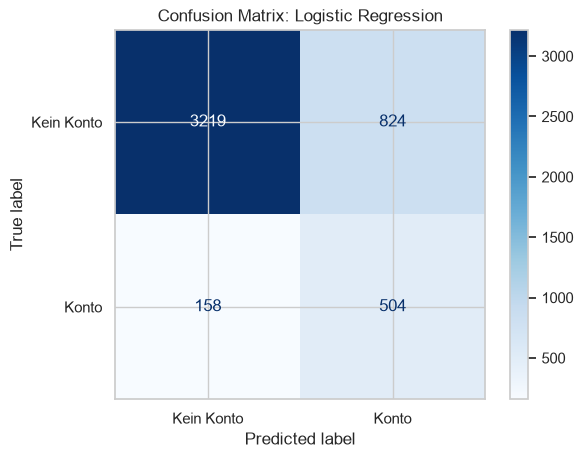


===== Random Forest =====
              precision    recall  f1-score   support

  Kein Konto      0.957     0.801     0.872      4043
       Konto      0.390     0.778     0.520       662

    accuracy                          0.798      4705
   macro avg      0.674     0.790     0.696      4705
weighted avg      0.877     0.798     0.822      4705



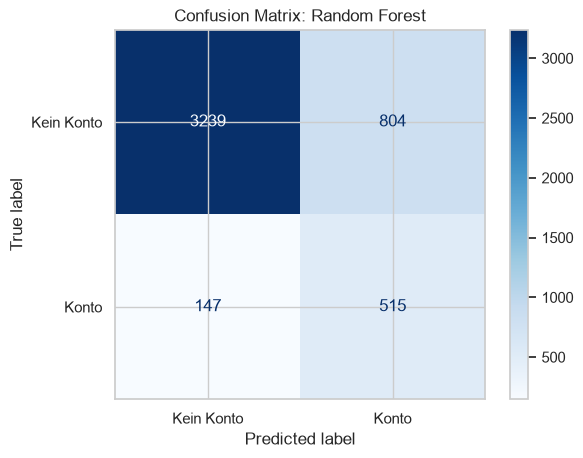

,Test F1,Test Precision,Test Recall,Test PR-AUC,Test ROC-AUC
Modell,,,,,
Logistic Regression,0.507,0.38,0.761,0.573,0.865
Random Forest,0.520,0.39,0.778,0.594,0.872


In [17]:
test_rows = []

for name in ["Logistic Regression", "Random Forest"]:
    pipe = models[name].fit(X_train, y_train)
    pred = pipe.predict(X_test)
    proba = pipe.predict_proba(X_test)[:, 1]

    print(f"\n===== {name} =====")
    print(classification_report(y_test, pred, digits=3,
                                target_names=["Kein Konto", "Konto"]))

    ConfusionMatrixDisplay.from_predictions(
        y_test, pred, display_labels=["Kein Konto", "Konto"], cmap="Blues")
    plt.title(f"Confusion Matrix: {name}")
    plt.show()

    test_rows.append({
        "Modell": name,
        "Test F1": f1_score(y_test, pred),
        "Test Precision": precision_score(y_test, pred),
        "Test Recall": recall_score(y_test, pred),
        "Test PR-AUC": average_precision_score(y_test, proba),
        "Test ROC-AUC": roc_auc_score(y_test, proba),
    })

test_results = pd.DataFrame(test_rows).set_index("Modell").round(3)
test_results

**Fazit:**

**Ergebnisse im Überblick** (Test-Set: 4.705 Personen, davon 662 mit Konto)

| | Logistic Regression | Random Forest |
|---|---|---|
| Richtig erkannte Kontoinhaber (TP) | 504 von 662 | 515 von 662 |
| Übersehene Kontoinhaber (FN) | 158 (23,9 %) | 147 (22,2 %) |
| Fehlalarme (FP) | 824 | 804 |
| Richtig erkannt "kein Konto" (TN) | 3.219 | 3.239 |
| Precision / Recall (Konto) | 0,380 / 0,761 | 0,390 / 0,778 |
| F1 / PR-AUC / ROC-AUC | 0,507 / 0,573 / 0,865 | 0,520 / 0,594 / 0,872 |

- **Logistic Regression:** Das Modell findet 504 der 662 Personen mit Konto (Recall 0,761). Von den 1.328 "Konto"-Vorhersagen stimmen nur 504 (Precision 0,380). Auf jeden Treffer kommen damit rund 1,6 Fehlalarme.
- **Random Forest:** Er findet 515 der 662 Kontoinhaber (Recall 0,778) bei 1.319 "Konto"-Vorhersagen (Precision 0,390). Gegenüber der Logistic Regression sind das 11 Treffer mehr und 20 Fehlalarme weniger. Er ist in allen Metriken leicht vorn (F1 +0,013, PR-AUC +0,021, ROC-AUC +0,007).
- **Abstand der Modelle:** Der Vorsprung des Random Forest entspricht dem Bild aus der Cross-Validation (dort +0,014 F1). Bei nur 662 positiven Fällen im Test-Set schwankt der F1 allein durch die zufällige Auswahl der Testdaten spürbar, ein Unterschied von 0,013 ist daher nicht belastbar. **Beide Modelle sind praktisch gleichwertig**, der Random Forest hat eine leichte Tendenz zum Vorteil.
- **Generalisierung:** Die Test-Werte (F1 0,507 bzw. 0,520) liegen sogar leicht über den CV-Werten (0,492 bzw. 0,506), mit ca. 0,014 Abstand bei beiden Modellen. Das ist im Rahmen der üblichen Streuung und spricht für **stabile Ergebnisse ohne erkennbares Overfitting auf dem Test-Set**. Die leicht höheren Test-Werte sollten nicht als echte Verbesserung gelesen werden.
- **Typische Fehlerart:** Es überwiegen **Fehlalarme**: Rund 20 % der Personen ohne Konto (824 von 4.043 bzw. 804 von 4.043) werden fälschlich als Kontoinhaber vorhergesagt. Die Modelle markieren insgesamt etwa 28 % aller Personen als "Konto", obwohl nur 14,1 % tatsächlich eines haben. Das ist die erwartbare Folge von `class_weight="balanced"`, das den Recall auf Kosten der Precision erhöht. Übersehen werden dagegen nur etwa 22 bis 24 % der Kontoinhaber.
- **Einordnung gegenüber der Untergrenze:** Die Precision von 0,38 bis 0,39 liegt etwa 2,7- bis 2,8-mal über dem Zufallsniveau von 0,141. Die Accuracy der Modelle (0,791 bzw. 0,798) ist **niedriger** als die des Dummys (0,859), obwohl die Modelle inhaltlich deutlich nützlicher sind, denn der Dummy findet keinen einzigen Kontoinhaber. Das bestätigt, dass Accuracy hier die falsche Metrik wäre.
- **Konsequenz für die Anwendung:** Wie gut ein Modell ist, hängt vom Einsatzzweck ab. Soll möglichst keine Zielgruppe übersehen werden (z. B. für Aufklärungsprogramme), ist der hohe Recall nützlich und die Fehlalarme sind verkraftbar. Soll die Vorhersage dagegen als belastbare Einzelaussage dienen, ist die Precision von unter 40 % zu niedrig. Der Schwellenwert ist dafür der wichtigste Stellhebel, und er sollte in der Iteration anhand der Cross-Validation optimiert und begründet werden.

**Hinweis:** Das Test-Set wurde damit einmal verwendet. Für Tuning, Feature Engineering und Modellvergleiche gilt ab jetzt nur noch die Cross-Validation auf dem Trainingsteil, damit das Test-Set für die Endbewertung unabhängig bleibt.

## 8. Einflussfaktoren

**Ziel:** Prüfen, welche Merkmale die Modelle nutzen, und mit den Ergebnissen der EDA abgleichen. Das stützt den erklärenden Teil des Produktwerts.

- **Logistic Regression:** Koeffizienten. Positive Werte erhöhen die Wahrscheinlichkeit für ein Konto, negative senken sie.
- **Random Forest:** Feature Importance, zusammengefasst pro ursprünglichem Merkmal (die One-Hot-Spalten werden aufsummiert).

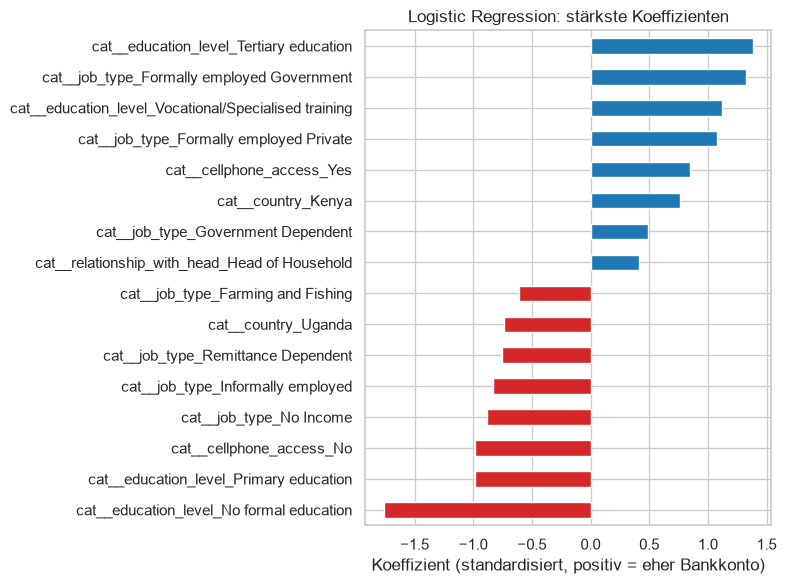

In [18]:
# Logistic Regression: Koeffizienten
lr = models["Logistic Regression"]
names = lr.named_steps["prep"].get_feature_names_out()
coefs = pd.Series(lr.named_steps["clf"].coef_[0], index=names).sort_values()

top = pd.concat([coefs.head(8), coefs.tail(8)])
plt.figure(figsize=(8, 6))
top.plot(kind="barh", color=["tab:red" if v < 0 else "tab:blue" for v in top])
plt.title("Logistic Regression: stärkste Koeffizienten")
plt.xlabel("Koeffizient (standardisiert, positiv = eher Bankkonto)")
plt.tight_layout()
plt.show()

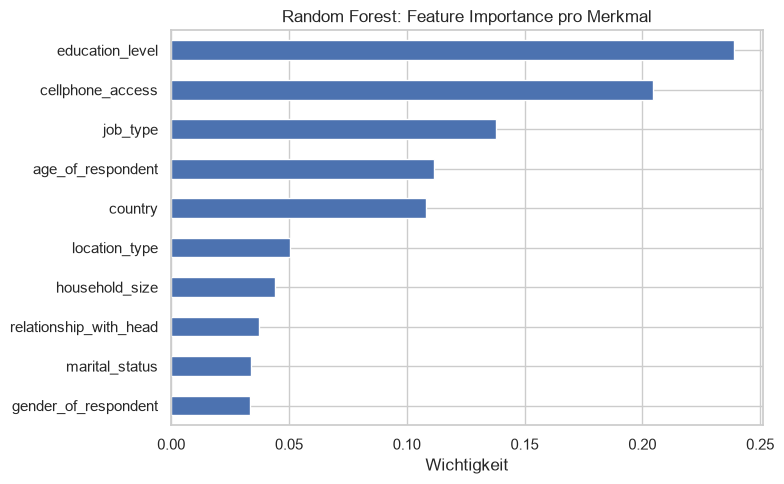

education_level           0.239
cellphone_access          0.204
job_type                  0.138
age_of_respondent         0.112
country                   0.108
location_type             0.050
household_size            0.044
relationship_with_head    0.037
marital_status            0.034
gender_of_respondent      0.033
dtype: float64

In [19]:
# Random Forest: Feature Importance, pro Originalmerkmal aufsummiert
rf = models["Random Forest"]
feat_names = rf.named_steps["prep"].get_feature_names_out()
imp = pd.Series(rf.named_steps["clf"].feature_importances_, index=feat_names)

def original_feature(name):
    name = name.replace("num__", "").replace("cat__", "")
    for c in NUM_COLS + CAT_COLS:
        if name == c or name.startswith(c + "_"):
            return c
    return name

imp_grouped = imp.groupby(original_feature).sum().sort_values(ascending=True)

plt.figure(figsize=(8, 5))
imp_grouped.plot(kind="barh")
plt.title("Random Forest: Feature Importance pro Merkmal")
plt.xlabel("Wichtigkeit")
plt.tight_layout()
plt.show()

imp_grouped.sort_values(ascending=False).round(3)

**Fazit:**
- **Logistic Regression:** Die stärksten positiven Einflüsse haben höhere Bildung (Tertiary, Vocational), formale Anstellung (Staat, privat), Handyzugang und Kenia. Die stärksten negativen Einflüsse haben keine formale Bildung bzw. nur Grundschule, kein Handyzugang, informelle oder fehlende Beschäftigung und Uganda.
- **Random Forest:** Die wichtigsten Merkmale sind education_level (0,239), cellphone_access (0,204) und job_type (0,138). Zusammen tragen sie etwa 58 % der Wichtigkeit.
- **Abgleich mit der EDA:** Beide Modelle bestätigen die EDA: Bildung, Beruf und Handyzugang sind die Haupttreiber, Land spielt eine Rolle, Stadt/Land und die Haushaltsmerkmale sind schwächer. Eine Abweichung gibt es beim Alter: Es liegt im Random Forest auf Platz 4 (0,112), obwohl die lineare Korrelation mit dem Ziel nahe null war. Das kann auf einen nichtlinearen Effekt hindeuten oder ein Artefakt sein, da die Feature Importance Merkmale mit vielen Werten bevorzugt. Das prüfen wir über die Quote nach Altersgruppen.
- **Hinweis:** Koeffizienten und Feature Importance zeigen Zusammenhänge, keine Ursachen. Korrelierte Merkmale (Bildung, Beruf, Handyzugang) teilen sich die Wichtigkeit, einzelne Plätze sind daher nicht exakt.

## 9. Ergebnisübersicht und Fazit

In [20]:
summary = cv_results[["CV F1", "F1 Std", "CV Precision", "CV Recall", "CV PR-AUC"]].join(
    test_results[["Test F1", "Test Precision", "Test Recall", "Test PR-AUC"]]
)
summary

,CV F1,F1 Std,CV Precision,CV Recall,CV PR-AUC,Test F1,Test Precision,Test Recall,Test PR-AUC
Modell,,,,,,,,,
Dummy (most_frequent),0.000,0.000,0.000,0.000,0.141,NaN,NaN,NaN,NaN
Logistic Regression,0.492,0.007,0.371,0.733,0.556,0.507,0.38,0.761,0.573
Random Forest,0.506,0.011,0.387,0.731,0.573,0.520,0.39,0.778,0.594


### Zusammenfassung

| Modell | CV F1 (± Std) | CV Precision | CV Recall | CV PR-AUC | Test F1 | Test Precision | Test Recall | Test PR-AUC |
|---|---|---|---|---|---|---|---|---|
| Dummy (most_frequent) | 0,000 | 0,000 | 0,000 | 0,141 | n/a | n/a | n/a | n/a |
| Logistic Regression | 0,492 ± 0,007 | 0,371 | 0,733 | 0,556 | 0,507 | 0,380 | 0,761 | 0,573 |
| Random Forest | 0,506 ± 0,011 | 0,387 | 0,731 | 0,573 | 0,520 | 0,390 | 0,778 | 0,594 |

**Gewinner:** Der Random Forest liegt mit CV-F1 = 0,506 und Test-F1 = 0,520 knapp vor der Logistic Regression (0,492 bzw. 0,507). Der Vorsprung von ca. 0,013 ist klein und liegt im Bereich der Streuung, beide Modelle sind praktisch gleichwertig.

**Einordnung gegenüber der Untergrenze:** Der Dummy erreicht eine Accuracy von 85,9 %, findet aber keine Person mit Bankkonto (F1 = 0). Die Modelle haben eine niedrigere Accuracy (ca. 79 bis 80 %), sind aber inhaltlich klar besser: Sie finden ca. 76 bis 78 % der Kontoinhaber, und ihre PR-AUC liegt etwa vier- bis fünfmal über dem Zufallsniveau von 0,141.

**Stärken und Schwächen:**
- Logistic Regression: gut erklärbar, keine Überanpassung, bildet aber nur lineare Effekte ab.
- Random Forest: leicht bessere Werte und erkennt Interaktionen automatisch, ist aber stärker überangepasst (Train-F1 0,581 gegenüber CV-F1 0,506) und schwerer zu erklären.
- Beide: hoher Recall, aber niedrige Precision (ca. 0,38 bis 0,39). Etwa 6 von 10 "Konto"-Vorhersagen sind Fehlalarme, eine Folge von `class_weight="balanced"`.

**Wichtigste Einflussfaktoren:** Bildung, Handyzugang und Berufstyp. Das bestätigt die EDA. Auffällig ist das Alter, das im Random Forest auf Platz 4 liegt, obwohl es linear kaum mit dem Ziel zusammenhängt.

**Nächste Schritte:**
1. Fehleranalyse: In welchen Gruppen (Land, Bildung, Beruf) irren die Modelle am häufigsten?
2. Feature Engineering aus der EDA: Interaktionen (Land × Bildung, Handyzugang × Bildung, Land × Stadt/Land), gezielte Zusammenfassung seltener Kategorien, Altersgruppen.
3. Weitere Algorithmen (z. B. Gradient Boosting) und Hyperparameter-Tuning, jeweils per Cross-Validation.
4. Optimierung des Schwellenwerts auf den F1-Score.